# 02 - Exploratory data analysis

All figures use the cleaned data (531 records). Each mode keeps the same colour in every chart.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
clean = pd.read_csv(C.Paths().processed / "clean_data.csv")
print(clean.shape)

(531, 41)


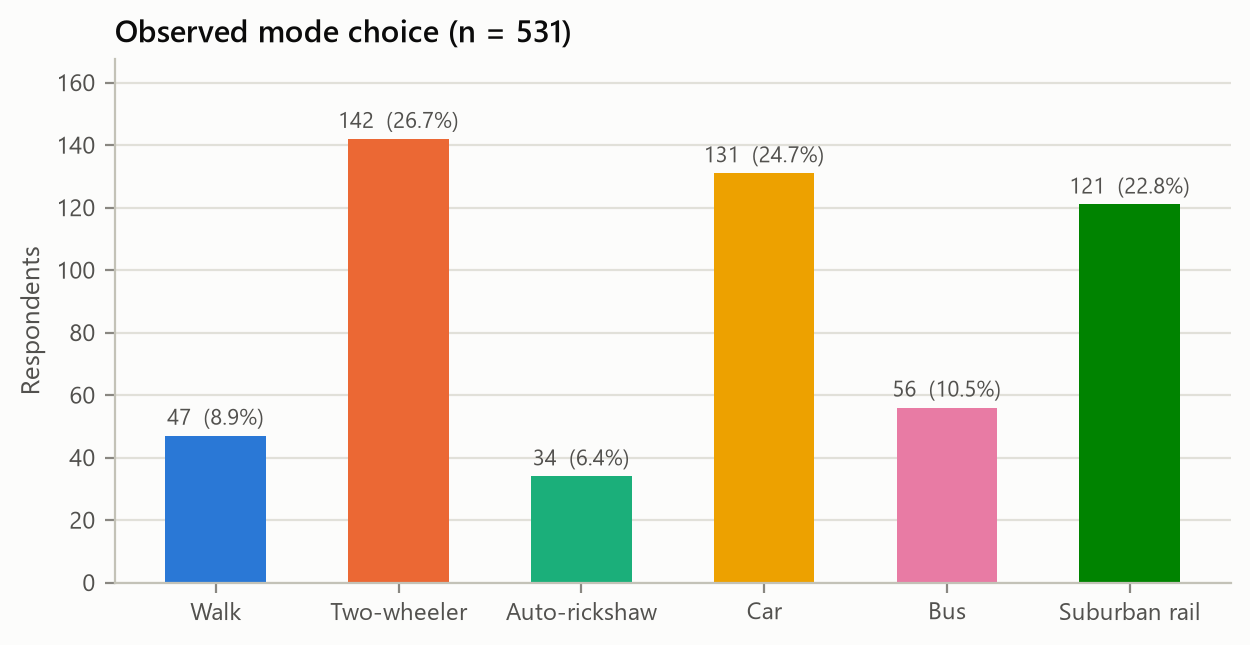

,mode,count,share_pct
0,Walk,47,8.9
1,Two-wheeler,142,26.7
2,Auto-rickshaw,34,6.4
3,Car,131,24.7
4,Bus,56,10.5
5,Suburban rail,121,22.8


In [2]:
fig("eda_mode_distribution.png", 700)
pd.read_csv(RES / "eda_mode_distribution.csv", index_col=0)

Two-wheeler (26.7%), car (24.7%) and suburban rail (22.8%) dominate; bus (10.5%), walking (8.9%)
and auto-rickshaw (6.4%) are minorities. With 34 auto users, any per-class metric for auto will be
noisy, which is why macro-averaged metrics matter.

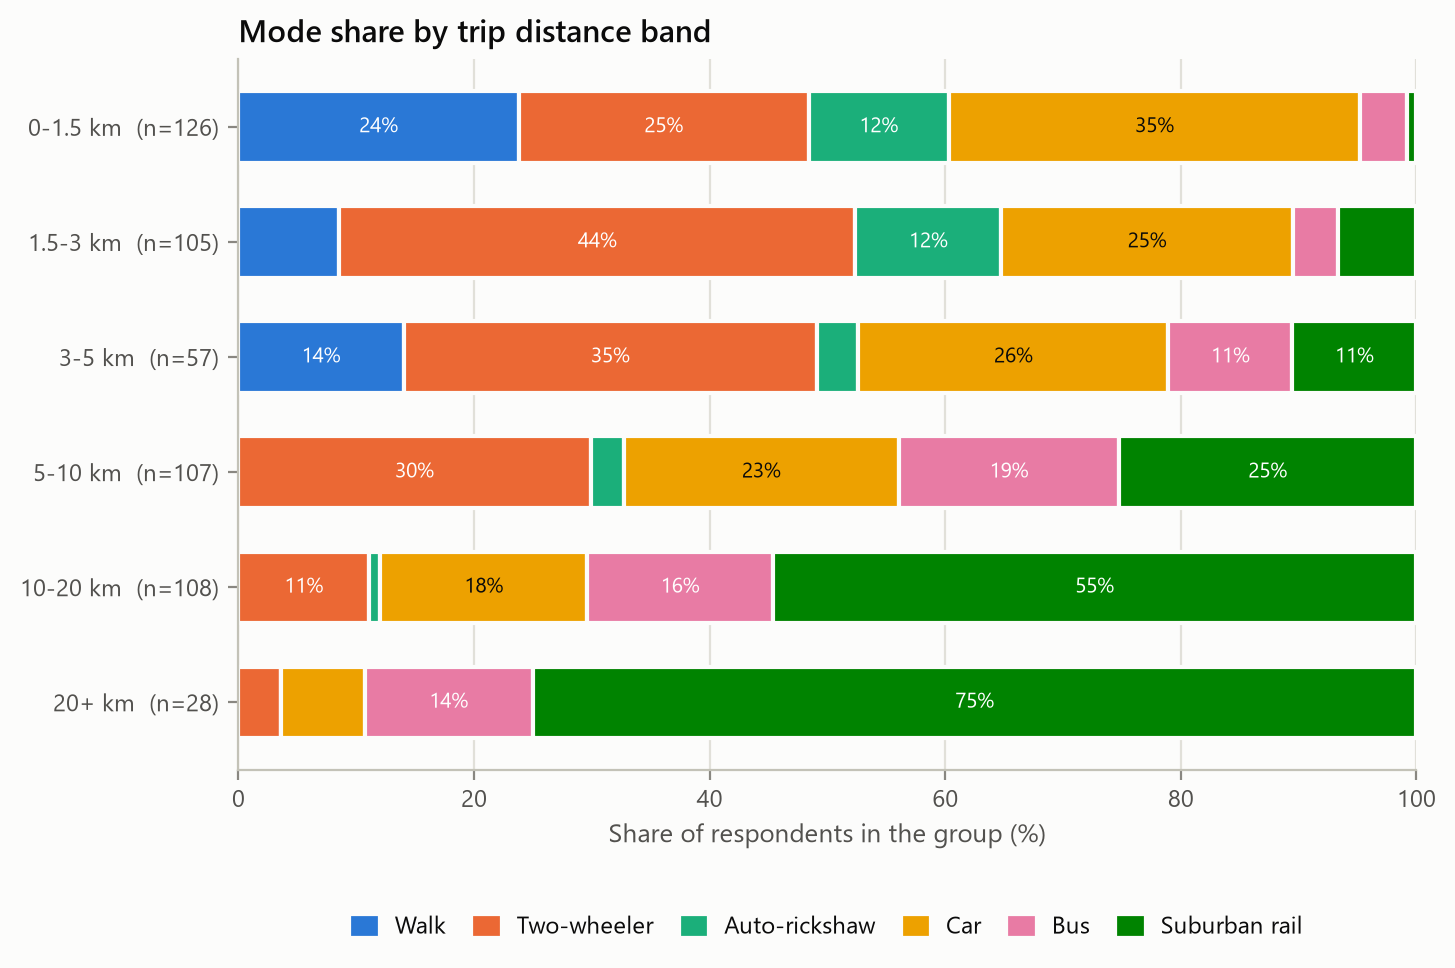

In [3]:
fig("eda_mode_by_distance_band.png", 800)

Distance is the main organising variable. Walking is only chosen up to 3.6 km. Rail grows from
under 1% of trips below 1.5 km to 55% at 10-20 km and 75% beyond 20 km, and bus peaks in the 5-10 km
band (19%). Car is strongest for short trips (35% below 1.5 km).

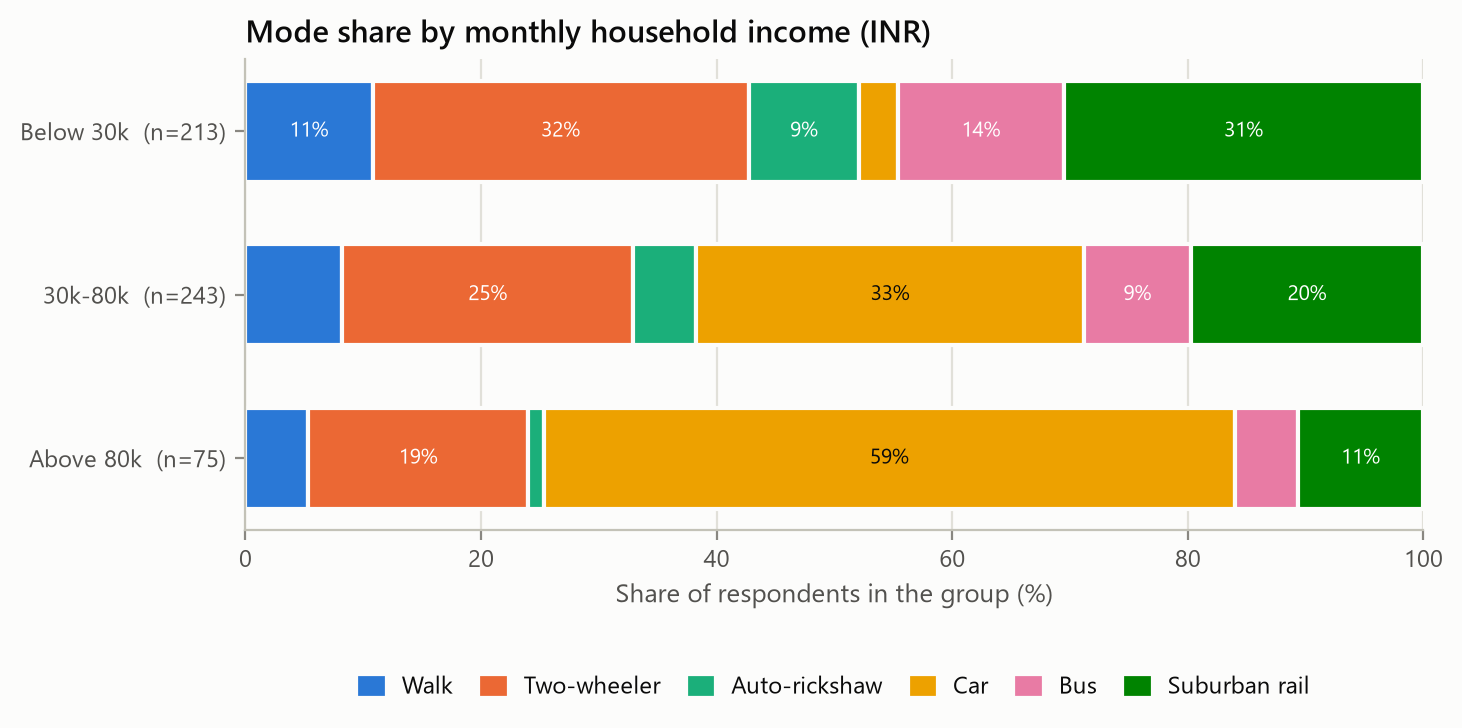

,walk,twow,auto,car,bus,train,n
Income,,,,,,,
1,10.8,31.9,9.4,3.3,14.1,30.5,213
2,8.2,24.7,5.3,32.9,9.1,19.8,243
3,5.3,18.7,1.3,58.7,5.3,10.7,75


In [4]:
fig("eda_mode_by_income.png", 800)
pd.read_csv(RES / "eda_by_income.csv", index_col=0)

Car use rises steeply with income: 3% in the lowest band, 33% in the middle and 59% in the highest.
Rail, bus and auto shares fall as income rises, so income should enter the car utility.

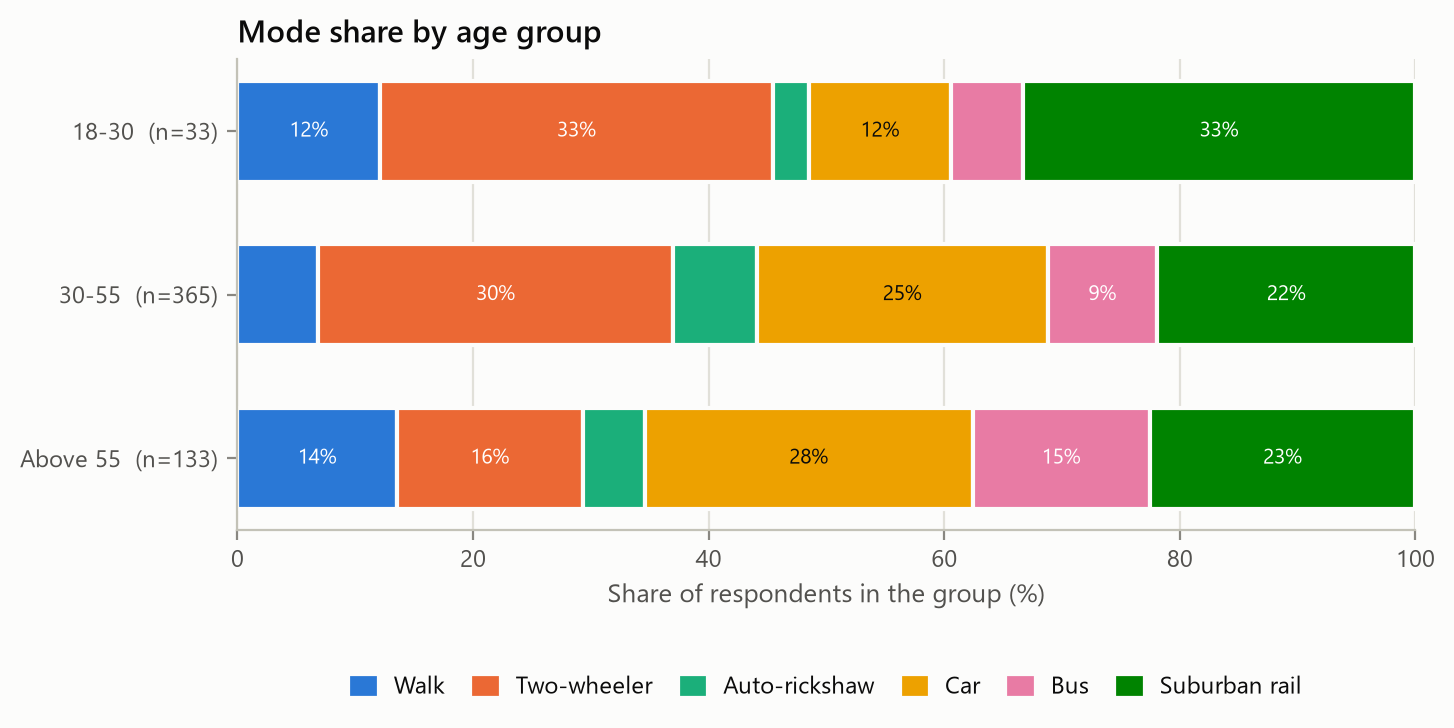

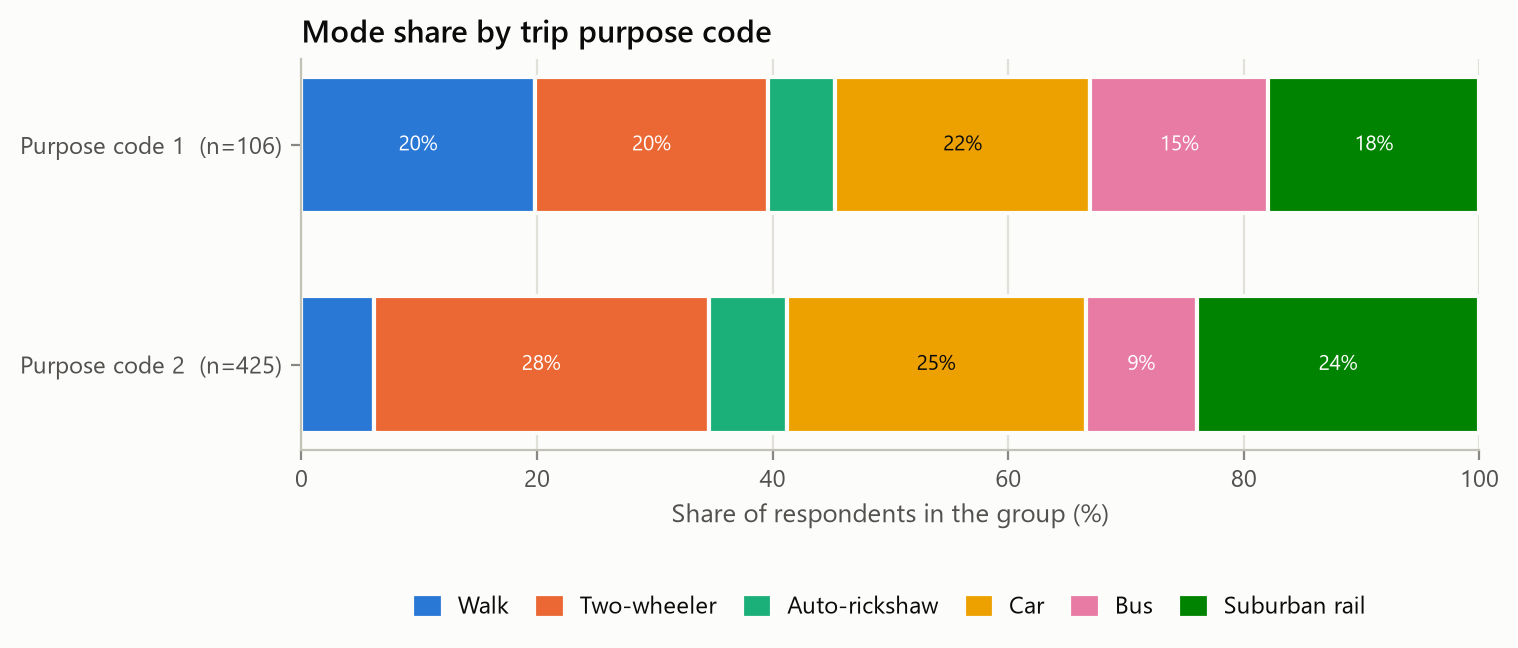

In [5]:
fig("eda_mode_by_age.png", 800)
fig("eda_mode_by_purpose.png", 800)

People over 55 walk (13.5%) and use the bus (15.0%) more than the 30-55 group. Purpose code 1
trips have much more walking (19.8% vs 6.1%) and bus (15.1% vs 9.4%), consistent with non-work
travel. The 18-30 group has only 33 people.

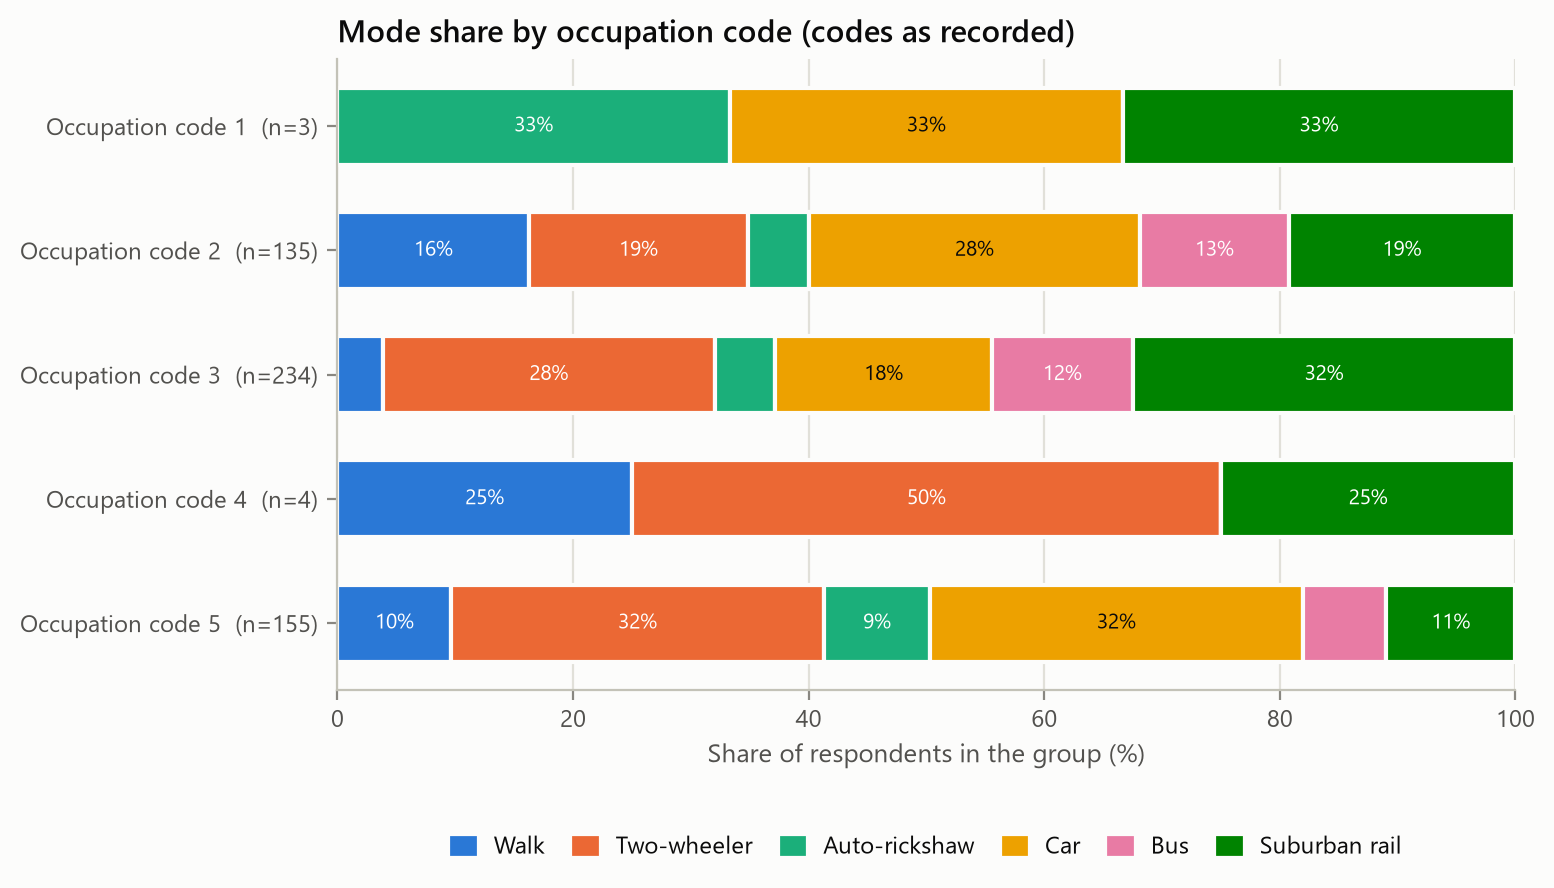

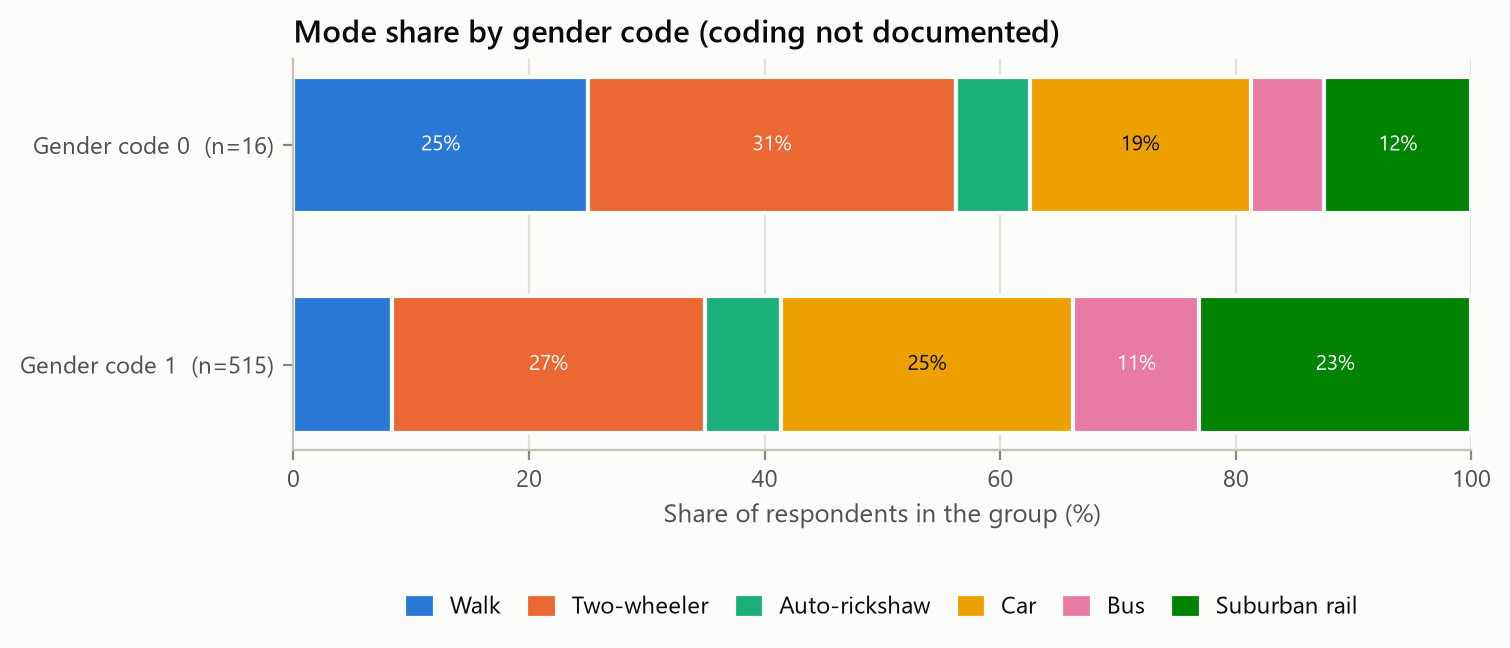

In [6]:
fig("eda_mode_by_occupation.png", 800)
fig("eda_mode_by_gender.png", 800)

Occupation codes 1 and 4 have 3 and 4 people, so their bars mean nothing. Code 3 has the highest rail
share (32.5%). Gender code 0 has only 16 people; the higher walking share there (25%) rests on four
individuals, so gender is left out of the choice model.

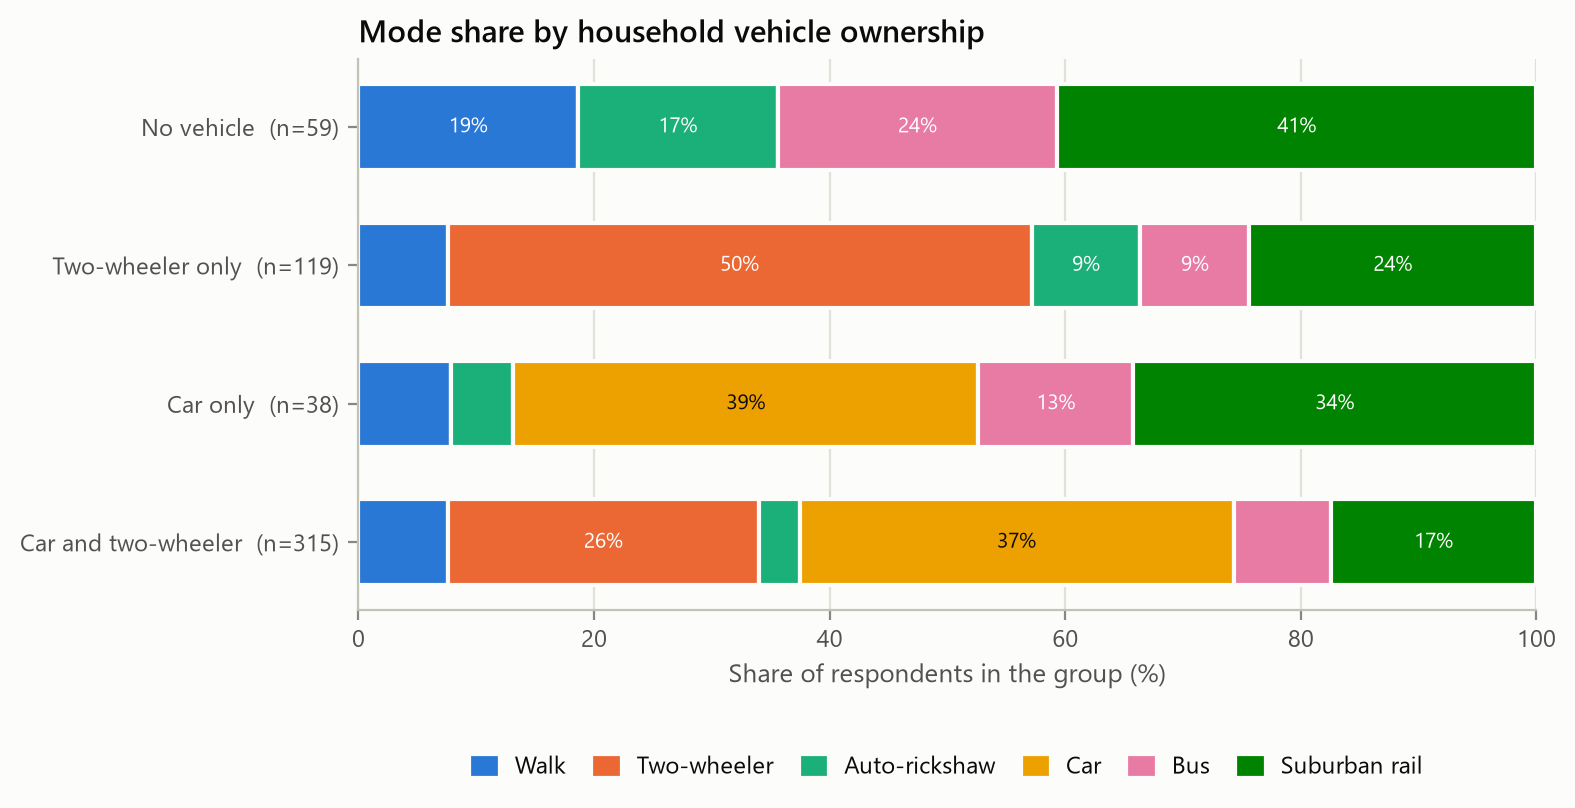

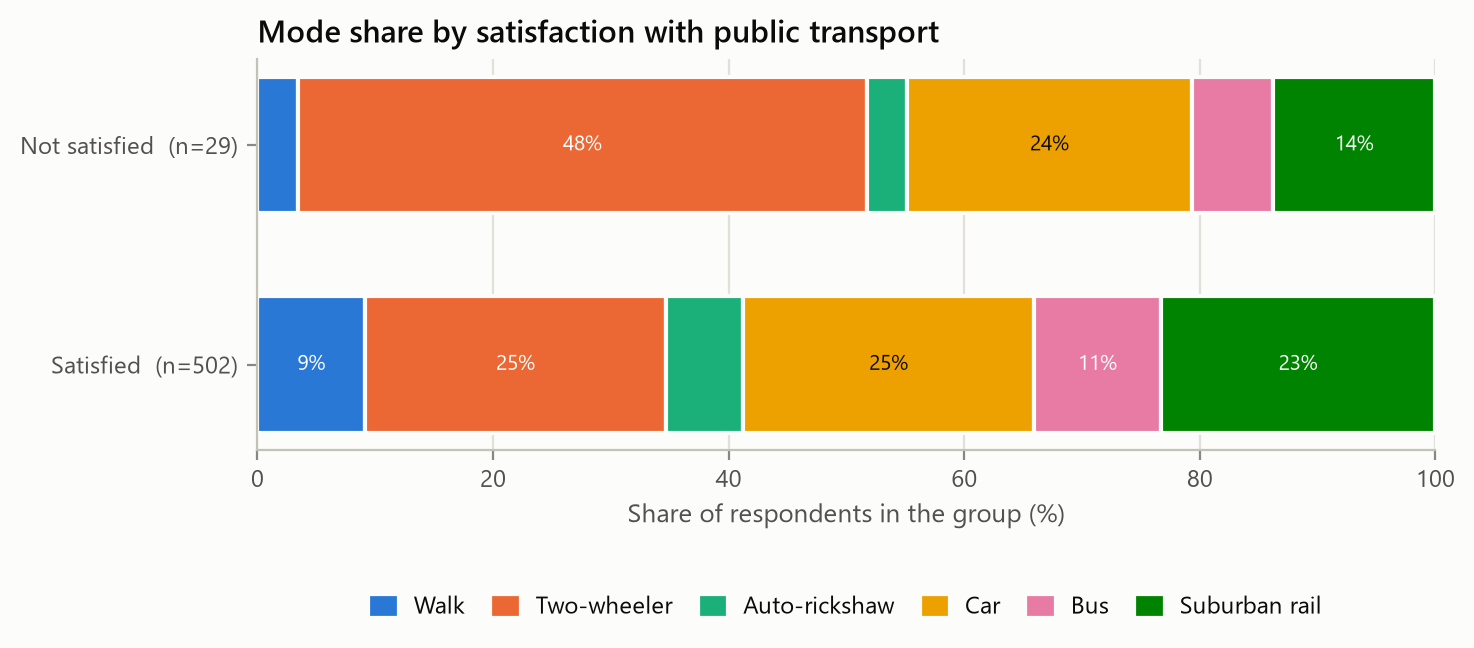

In [7]:
fig("eda_mode_by_vehicle_ownership.png", 800)
fig("eda_mode_by_sapt.png", 800)

Households with no vehicle split between rail (40.7%), bus (23.7%), walking (18.6%) and auto
(16.9%). Two-wheeler-only households use their two-wheeler for half of trips. Only 29 people are
dissatisfied with public transport, and they use two-wheelers far more (48% vs 25%).

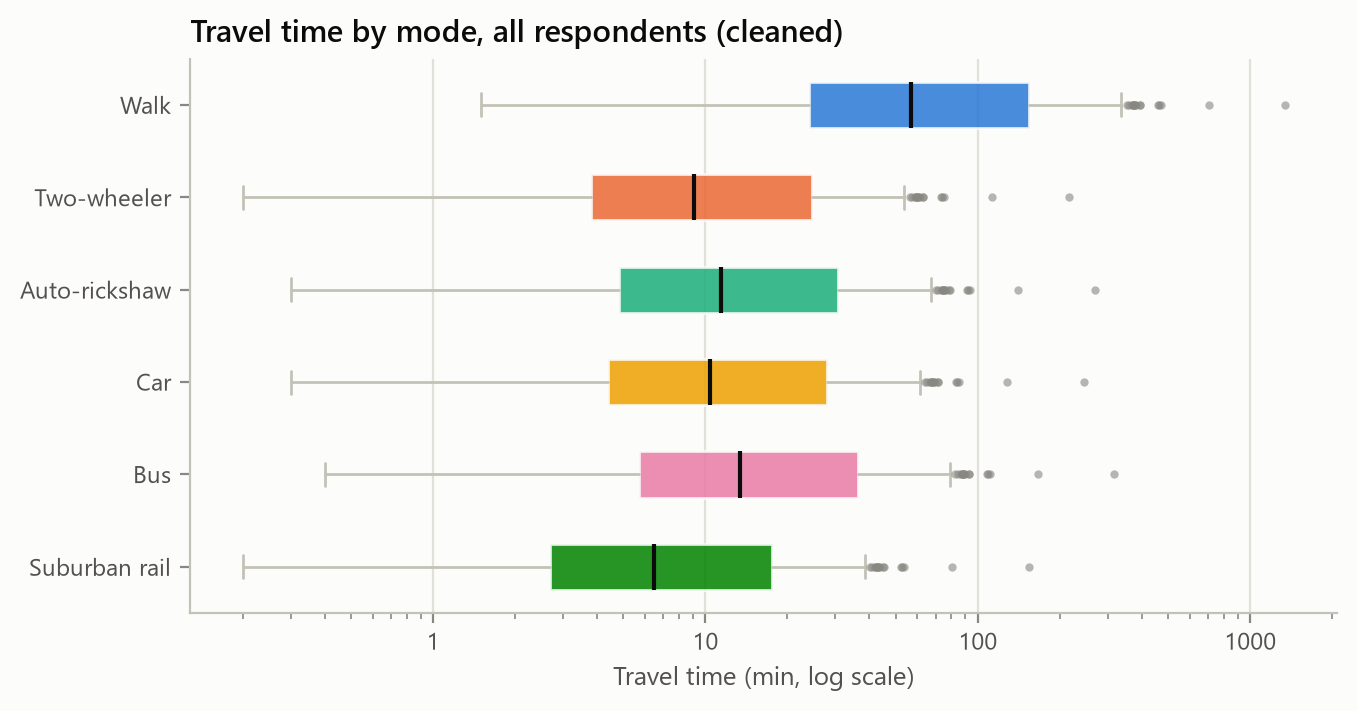

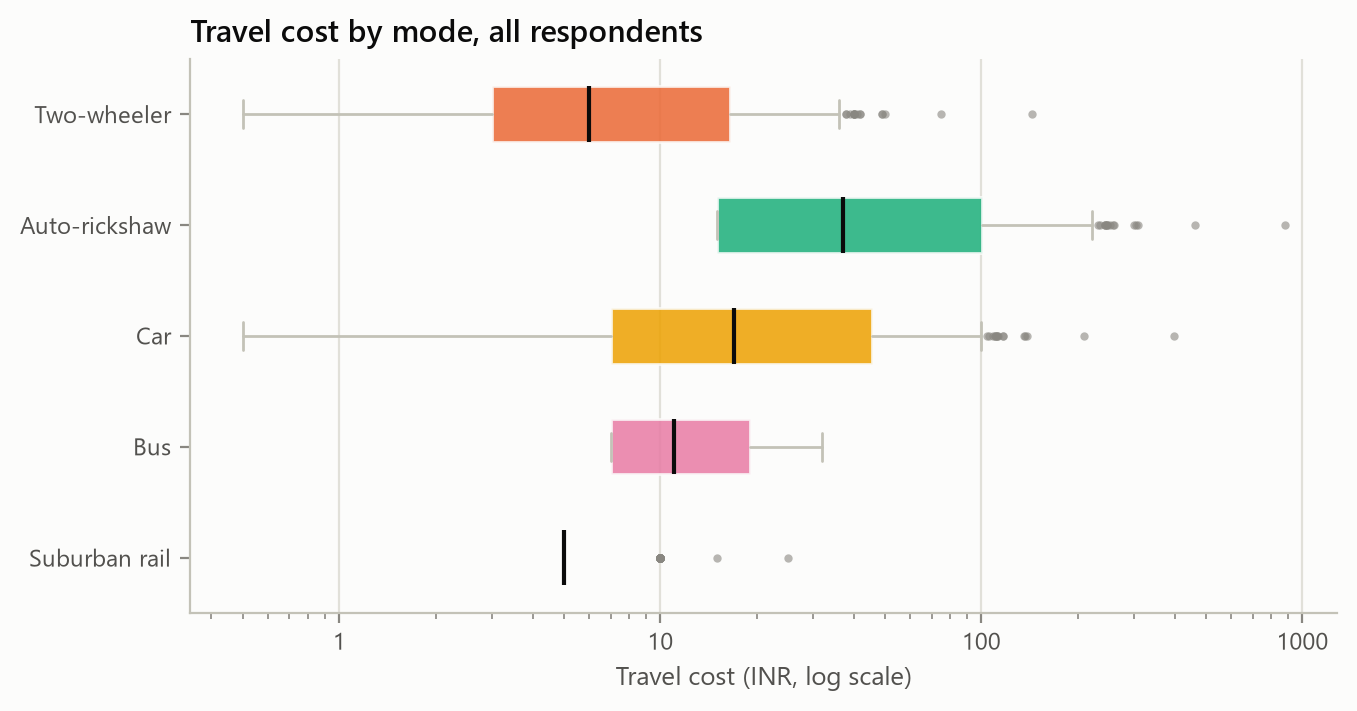

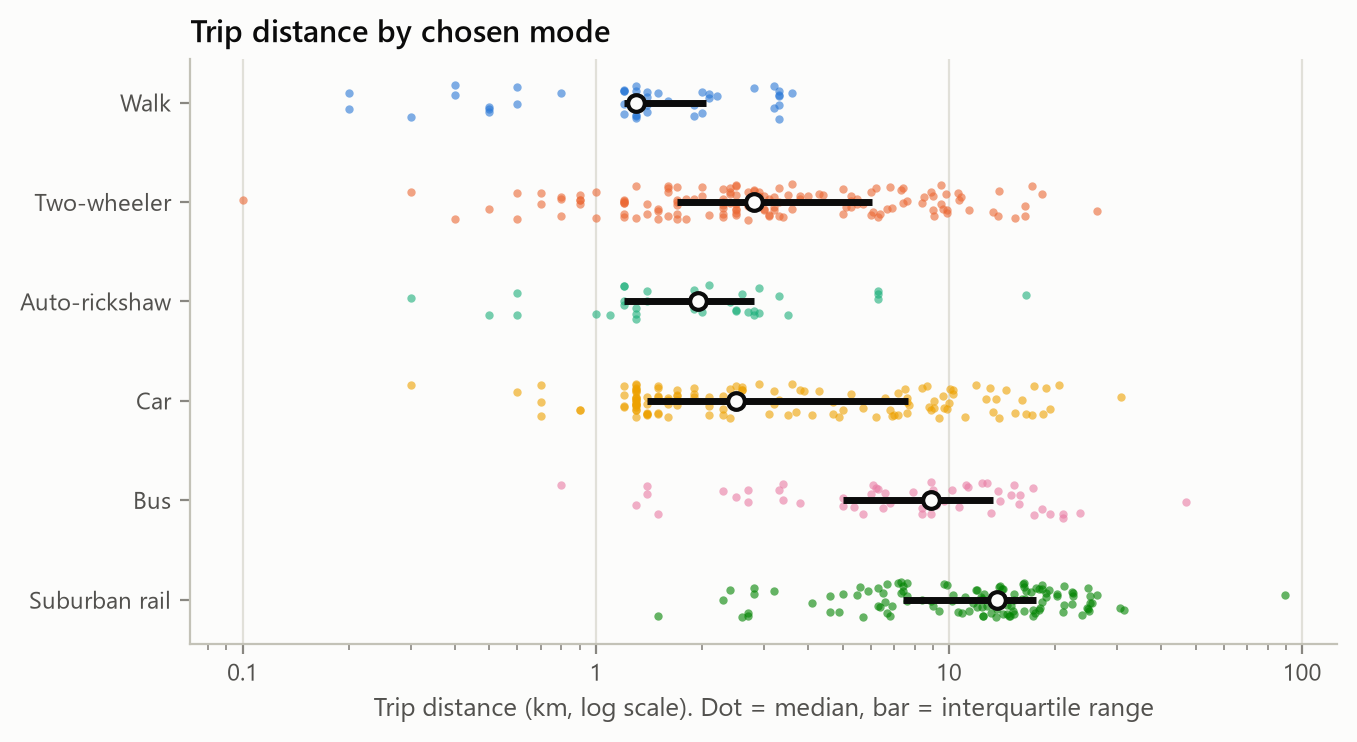

,count,25%,50%,75%,max
mode,,,,,
walk,47.0,1.2,1.30,2.05,3.6
twow,142.0,1.7,2.80,6.07,26.3
auto,34.0,1.2,1.95,2.80,16.5
car,131.0,1.4,2.50,7.65,30.8
bus,56.0,5.0,8.90,13.35,47.0
train,121.0,7.4,13.70,17.70,89.7


In [8]:
fig("eda_travel_time.png", 750)
fig("eda_travel_cost.png", 750)
fig("eda_distance_by_choice.png", 750)
pd.read_csv(RES / "eda_distance_by_choice.csv", index_col=0)

Median distances by chosen mode: walk 1.3 km, auto 2.0, car 2.5, two-wheeler 2.8, bus 8.9 and rail
13.7 km. The time and cost box plots look like rescaled copies of each other because they are
rescaled copies of distance. Rail fares barely vary (INR 5 for 95% of trips).

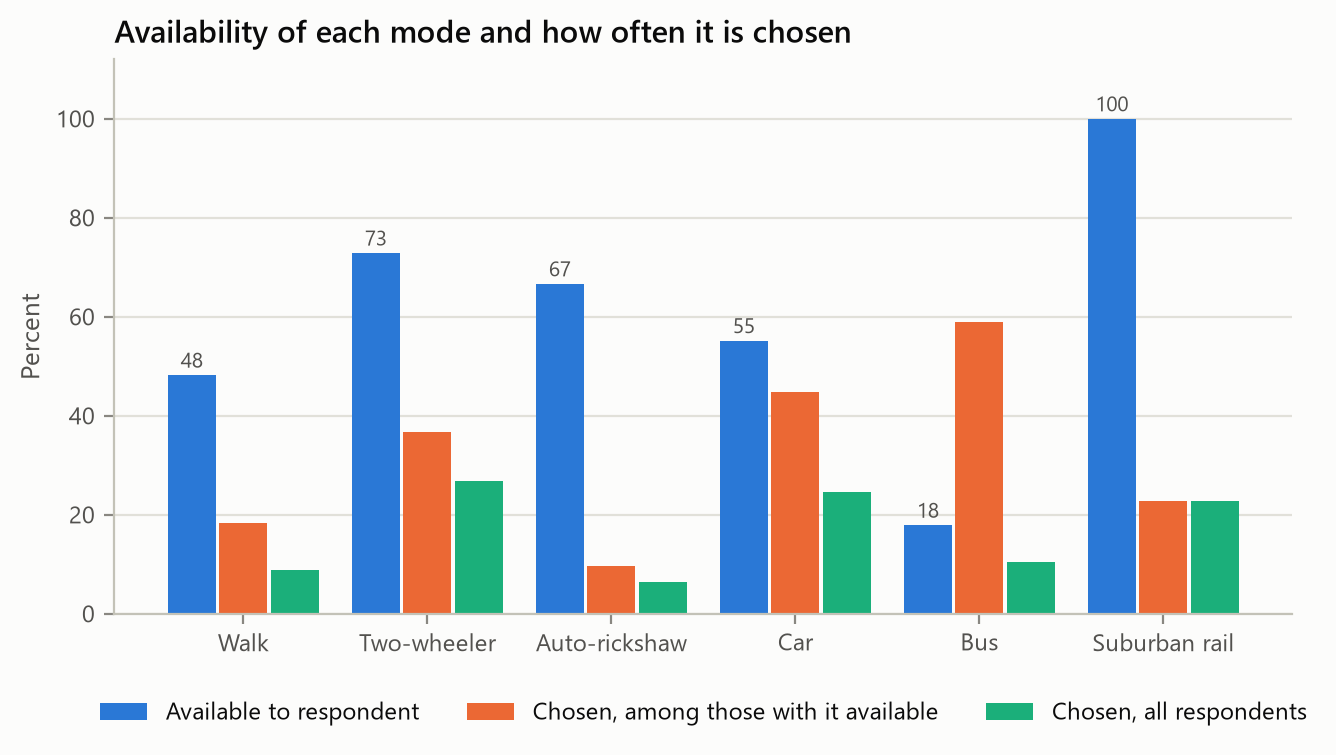

,mode,available_pct,chosen_pct,chosen_when_available_pct
0,Walk,48.2,8.9,18.4
1,Two-wheeler,72.9,26.7,36.7
2,Auto-rickshaw,66.7,6.4,9.6
3,Car,55.2,24.7,44.7
4,Bus,17.9,10.5,58.9
5,Suburban rail,100.0,22.8,22.8


In [9]:
fig("eda_availability_vs_choice.png", 800)
pd.read_csv(RES / "eda_availability.csv", index_col=0)

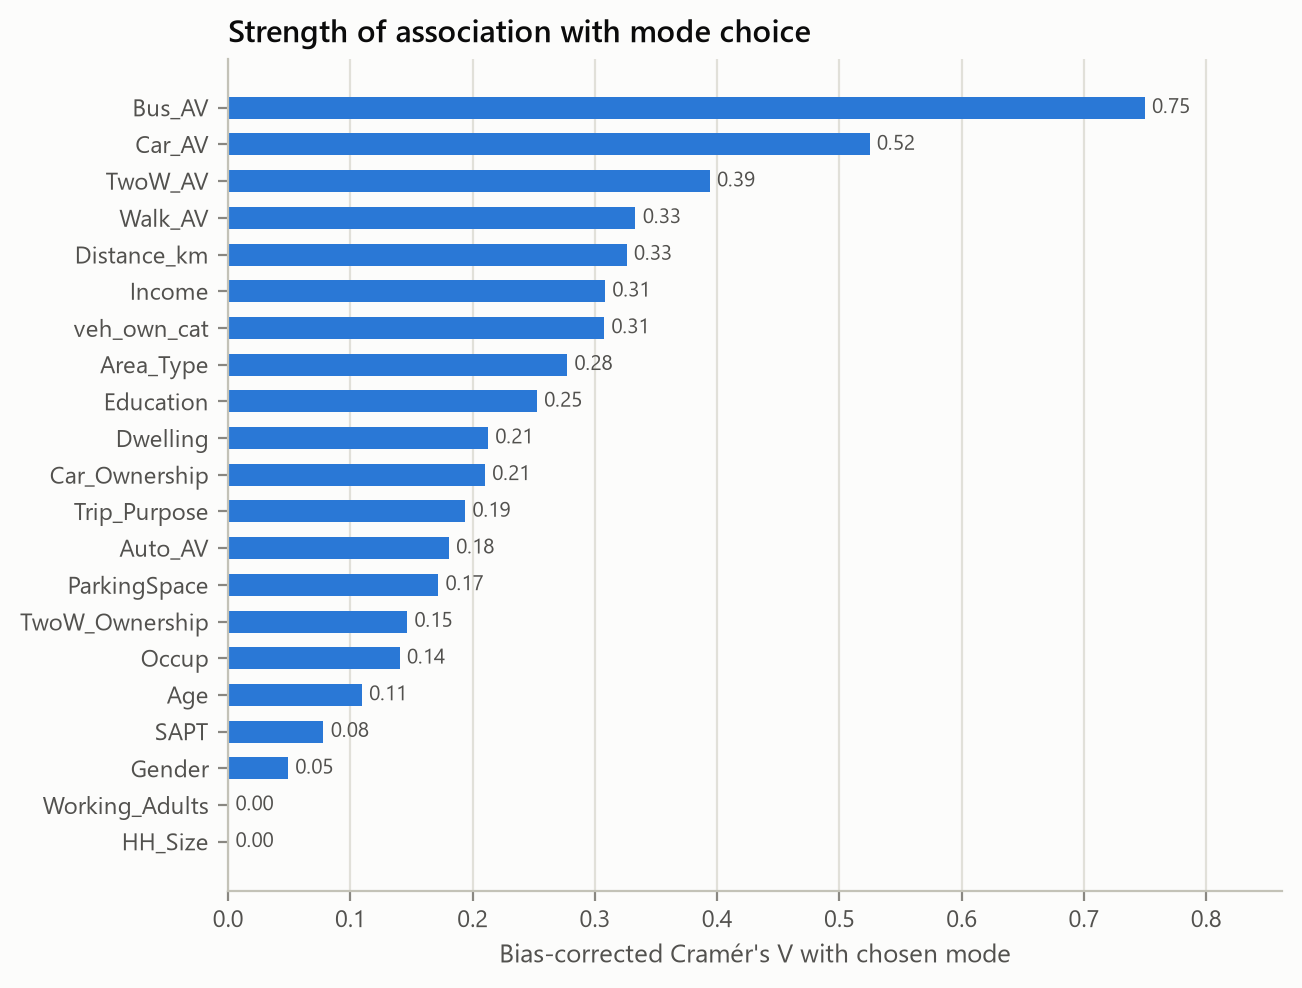

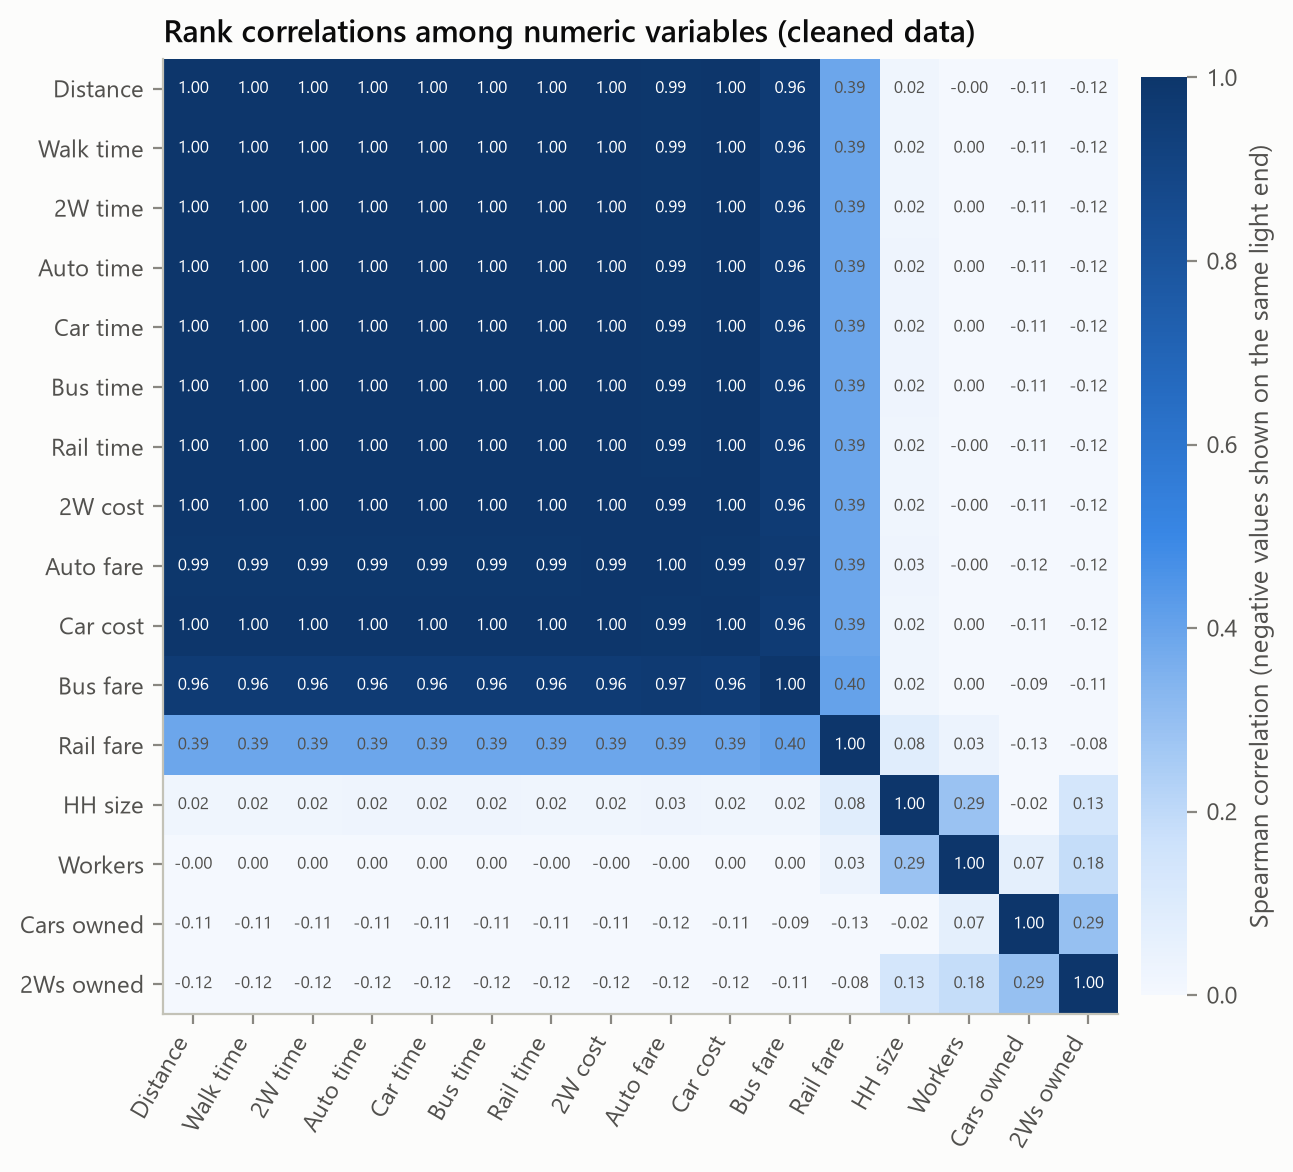

In [10]:
fig("eda_association_with_choice.png", 650)
fig("eda_numeric_correlation.png", 650)

Bus availability has the strongest association with the chosen mode (Cramér's V 0.75), followed by
car and two-wheeler availability, distance, income and vehicle ownership. Household size and the
number of workers show no association at all. The correlation heatmap shows distance, all six times
and most costs at |rho| close to 1, the collinearity found in the audit.